# MC833 · Projeto 3 — Parte 2: Modelamento preditivo com LSTM

**Previsão de tráfego de rede com redes neurais recorrentes** · comparando a Internet de **2007** e de **2024**

## Contexto
Na parte de EDA você conheceu o throughput dos dois traces MAWI (sábado, 10/02, 14:00 JST, em 2007 e em 2024). Agora você vai **treinar uma LSTM para prever o throughput do próximo segundo** a partir dos segundos anteriores, e **comparar os modelos dos dois anos**.

## Como funciona
* **Entrada:** uma janela deslizante com os últimos `look_back` valores do throughput (ex.: 10 s).
* **Saída:** o valor previsto para o segundo seguinte.
* **Rede:** uma camada **LSTM** + uma camada **densa** (arquitetura enxuta).
* **Treino/teste:** primeiros 80% do tempo para treino, últimos 20% para teste (sem embaralhar).
* **Métrica:** **MSE** (erro quadrático médio). Mostramos também o RMSE em Mbps e o RMSE relativo à média, que permite comparar 2007 e 2024.

## O que você vai entregar (seção "Modelamento preditivo" do relatório)
| Item do relatório | Onde |
|---|---|
| Descrição da abordagem LSTM (arquitetura, hiperparâmetros, divisão treino/teste, normalização) | Tarefa T1 + exemplo E2 |
| Gráfico **real × previsto** no conjunto de teste | T1 e T2 |
| Tabela de **MSE** por janela (10, 20 e 30) | T2 |
| Modelo de cada ano **salvo** | T2 |
| **Comparação 2007 × 2024**: matriz modelo × teste e gráficos | T3 |
| Análise: onde o modelo acerta e erra, e o que a comparação mostra | Seção 5 |

## Como usar este notebook
* Rode as células **em ordem**. Os **exemplos** (E1 e E2) já estão prontos.
* Complete as células marcadas com `# TODO` nas **tarefas** T1–T3. O **bônus** (B1) é opcional.
* **Fixe as sementes** (`fixar_sementes`) e **comente seu código**.
* Dica: no Colab, use *Ambiente de execução → Alterar tipo → GPU* se quiser acelerar, mas as séries são pequenas e a CPU basta.
* Salve as figuras do relatório com `plt.savefig('nome.png', dpi=200, bbox_inches='tight')` antes de `plt.show()`.

## 1. Setup

In [1]:
import os, sys, json, random, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'           # menos mensagens do TensorFlow
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow import keras

warnings.filterwarnings('ignore')
tf.get_logger().setLevel('ERROR')                 # silencia avisos repetitivos do TensorFlow
EM_COLAB = 'google.colab' in sys.modules
if EM_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

# ============================ CONFIGURAÇÃO ============================
PASTA_DADOS = './dados'      # pasta com uma subpasta por trace (a mesma da parte de EDA)
TRACES = {'2007': '200702101400', '2024': '202402101400'}
PASTA_MODELOS = 'modelos'      # onde salvar os modelos treinados (crie sua própria pasta)

ESCALA_MS = 1000               # granularidade da série: 1 ponto por segundo (tente 100 para mais pontos)
FRAC_TREINO = 0.8              # 80% do tempo para treino, 20% para teste (divisão temporal, sem embaralhar)
SEMENTE = 42                   # reprodutibilidade
# ======================================================================
os.makedirs(PASTA_MODELOS, exist_ok=True)
print('TensorFlow', tf.__version__, '| Keras', keras.__version__)

TensorFlow 2.21.0 | Keras 3.15.1


### Funções auxiliares e carga dos dados
Não precisa alterá-las; leia os comentários.

In [2]:
# ---------- Estilo: cor do ano = cor do MODELO treinado naquele ano; a série real é sempre cinza ----------
COR = {'2007': '#2a78d6', '2024': '#eb6834'}
COR_REAL = '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.labelsize': 10, 'legend.frameon': False, 'legend.fontsize': 9, 'lines.linewidth': 1.2})

# ---------- Dados: a série de throughput (Mbps) de cada ano ----------
def carregar_serie(ano, escala_ms=ESCALA_MS):
    """Lê a série fina (10 ms) do ano e soma em intervalos de `escala_ms`. Devolve o throughput em Mbps
    como pd.Series indexada pelo tempo (s). (O último intervalo, se incompleto, é descartado.)"""
    tid = TRACES[ano]
    df = pd.read_parquet(os.path.join(PASTA_DADOS, tid, f'{tid}_serie_10ms.parquet'), columns=['bytes'])
    fator = escala_ms // 10
    n = (len(df) // fator) * fator
    soma = df['bytes'].values[:n].reshape(-1, fator).sum(axis=1)
    return pd.Series(soma * 8 / (escala_ms / 1000) / 1e6, index=np.arange(len(soma)) * escala_ms / 1000, name='Mbps')

SERIES = {ano: carregar_serie(ano) for ano in TRACES}
for ano, s in SERIES.items():
    print(f'{ano}: {len(s)} pontos | média {s.mean():.1f} Mbps | mín {s.min():.1f} | máx {s.max():.1f}')

# ---------- Reprodutibilidade ----------
def fixar_sementes(semente=SEMENTE):
    random.seed(semente); np.random.seed(semente); keras.utils.set_random_seed(semente)

# ---------- Janelas deslizantes ----------
def create_sequences(data, look_back):
    """data: array (n, 1). Devolve X (n-look_back, look_back, 1) e y (n-look_back, 1):
    cada amostra usa `look_back` valores seguidos para prever o valor seguinte."""
    X, y = [], []
    for i in range(len(data) - look_back):
        X.append(data[i:i + look_back])
        y.append(data[i + look_back])
    return np.array(X), np.array(y)

# ---------- Métricas ----------
def metricas(real, prev):
    """MSE e RMSE em Mbps (unidades reais) e RMSE relativo à média da série real (permite comparar 2007 e 2024)."""
    real, prev = np.asarray(real), np.asarray(prev)
    mse = float(np.mean((real - prev) ** 2))
    return {'MSE (Mbps²)': mse, 'RMSE (Mbps)': mse ** 0.5, 'RMSE/média (%)': 100 * mse ** 0.5 / float(np.mean(real))}

# ---------- Gráfico real × previsto ----------
def plotar_real_previsto(ax, t, real, prev, cor, titulo, rotulo_prev='prevista'):
    """Curva real (cinza) × curva prevista (cor do modelo) no conjunto de teste."""
    ax.plot(t, real, color=COR_REAL, lw=1.3, label='real')
    ax.plot(t, prev, color=cor, lw=1.3, label=rotulo_prev)
    ax.set_title(titulo); ax.set_xlabel('tempo (s)'); ax.set_ylabel('Mbps'); ax.legend()

2007: 900 pontos | média 94.3 Mbps | mín 66.6 | máx 123.7
2024: 899 pontos | média 1229.1 Mbps | mín 483.0 | máx 5591.1


## 2. Exemplos resolvidos

### Exemplo E1 · A série e a divisão treino/teste

**Objetivo:** Ver a série de throughput (1 ponto por segundo) de cada ano e onde ela é dividida em **treino (80%)** e **teste (20%)**. A divisão é **temporal**: o teste é sempre o final da série, o "futuro" que o modelo nunca viu.

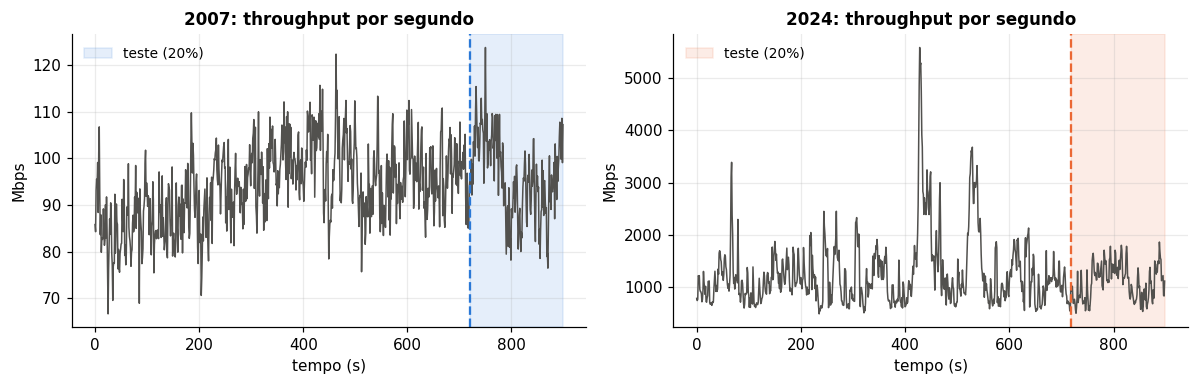

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, ano in zip(axs, SERIES):
    s = SERIES[ano]; corte = s.index[int(len(s) * FRAC_TREINO)]
    ax.plot(s.index, s.values, color=COR_REAL, lw=1)
    ax.axvline(corte, color=COR[ano], lw=1.5, ls='--')
    ax.axvspan(corte, s.index[-1], color=COR[ano], alpha=0.12, label='teste (20%)')
    ax.set_title(f'{ano}: throughput por segundo'); ax.set_xlabel('tempo (s)'); ax.set_ylabel('Mbps'); ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

### Exemplo E2 · Preparação: normalização e janelas deslizantes

**Objetivo:** Transformar a série em exemplos de treino: cada **janela** de `look_back` valores seguidos (entrada `X`) deve prever o valor seguinte (alvo `y`). Leia com atenção os comentários: eles explicam por que o *scaler* é ajustado só no treino. A função `preparar_dados` será usada em todas as tarefas.

In [4]:
def preparar_dados(serie, look_back, frac_treino=FRAC_TREINO, scaler=None):
    """Prepara a série para a LSTM:
       1) separa os primeiros `frac_treino` (treino) dos últimos (teste), **sem embaralhar** (é uma série temporal);
       2) normaliza para [0, 1] com MinMaxScaler ajustado **só no treino** (se ajustasse na série toda, o teste
          "vazaria" informação para o treino); se `scaler` for dado, ele é reutilizado em vez de ajustado;
       3) cria as janelas deslizantes de tamanho `look_back`.
       Cada alvo de teste é um instante do conjunto de teste; sua janela de entrada olha só para o passado
       (as primeiras janelas de teste usam os últimos pontos do treino)."""
    valores = serie.values.reshape(-1, 1)
    n_treino = int(len(valores) * frac_treino)
    if scaler is None:
        scaler = MinMaxScaler().fit(valores[:n_treino])
    esc = scaler.transform(valores)
    X, y = create_sequences(esc, look_back)
    posicao_alvo = np.arange(look_back, len(esc))              # instante (índice) de cada alvo y
    tr, te = posicao_alvo < n_treino, posicao_alvo >= n_treino
    return dict(X_tr=X[tr], y_tr=y[tr], X_te=X[te], y_te=y[te], scaler=scaler,
                t_te=serie.index.values[posicao_alvo[te]], n_treino=n_treino)

def prever(modelo, d):
    """Previsões do modelo no conjunto de teste, de volta à escala real (Mbps). Devolve (real, previsto)."""
    prev = d['scaler'].inverse_transform(modelo.predict(d['X_te'], verbose=0)).ravel()
    real = d['scaler'].inverse_transform(d['y_te']).ravel()
    return real, prev

def persistencia(d):
    """Baseline sem aprendizado: prever que o próximo valor é igual ao último valor observado."""
    return d['scaler'].inverse_transform(d['X_te'][:, -1, :]).ravel()

# Demonstração com a série de 2007 e janela de 10 passos
d = preparar_dados(SERIES['2007'], look_back=10)
print('X_tr:', d['X_tr'].shape, '| y_tr:', d['y_tr'].shape, '| X_te:', d['X_te'].shape, '| y_te:', d['y_te'].shape)
print(f"treino = primeiros {d['n_treino']} pontos; escala do scaler (treino): "
      f"{float(d['scaler'].data_min_[0]):.1f} a {float(d['scaler'].data_max_[0]):.1f} Mbps")

X_tr: (710, 10, 1) | y_tr: (710, 1) | X_te: (180, 10, 1) | y_te: (180, 1)
treino = primeiros 720 pontos; escala do scaler (treino): 66.6 a 122.3 Mbps


## 3. Tarefas

### Tarefa T1 · A LSTM: construir, treinar e avaliar (2007, janela de 10)

**Objetivo:** Implementar a arquitetura **enxuta**: **uma camada LSTM + uma camada densa** que prevê o próximo ponto. Treinar com os dados de treino de **2007** (janela de 10 s) e avaliar no teste com o **MSE**. Plotar **real × previsto** e a **curva de perda**.

**Dados:** `preparar_dados(SERIES["2007"], look_back=10)` (exemplo E2), `prever(modelo, d)`, `metricas(real, prev)` e `plotar_real_previsto(...)`.

**Dicas:**

* `keras.Sequential([keras.layers.Input(shape=(look_back, 1)), keras.layers.LSTM(32), keras.layers.Dense(1)])`.
* `modelo.compile(optimizer="adam", loss="mse")`.
* `modelo.fit(X_tr, y_tr, epochs=..., batch_size=..., validation_split=0.1, callbacks=[EarlyStopping(...)], verbose=0)`: o `validation_split` reserva o final do treino para validação, e o `EarlyStopping` (com `restore_best_weights=True`) para quando a validação para de melhorar.
* Chame `fixar_sementes(SEMENTE)` antes de treinar, para o resultado ser reproduzível.
* Registre os hiperparâmetros usados (`epochs`, `batch_size`, nº de unidades): vão para o relatório.

Métricas do modelo LSTM (2007): 40.667 | 6.377 | 6.63%
Métricas da persistência (2007): 38.179 | 6.179 | 6.43%


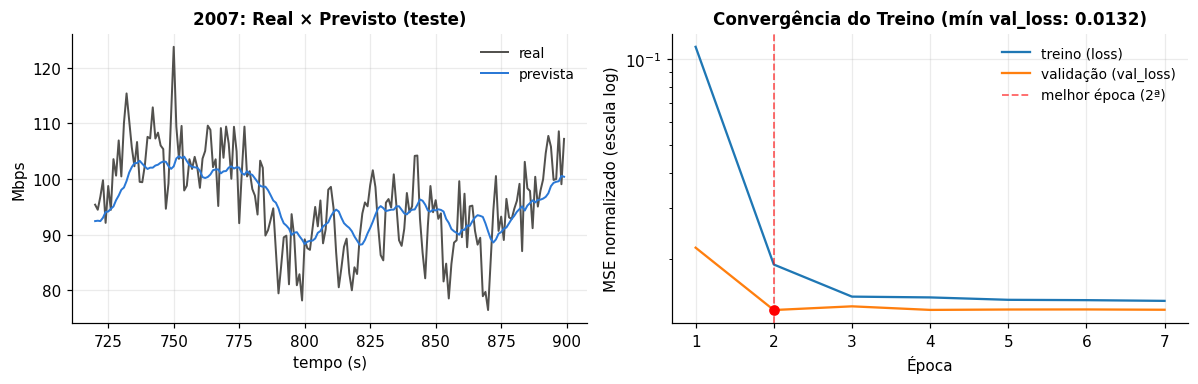

In [6]:
def construir_modelo(look_back, unidades=32):
    """Arquitetura enxuta: uma camada LSTM seguida de uma camada densa (saída: o próximo ponto)."""
    # TODO: keras.Sequential com Input, LSTM e Dense(1); compile com otimizador adam e perda mse; devolva o modelo
    modelo = keras.Sequential([keras.layers.Input(shape=(look_back, 1)), keras.layers.LSTM(32), keras.layers.Dense(1)])
    modelo.compile(optimizer='adam', loss='mse')
    return modelo

def treinar(dados, look_back, epochs=50, batch_size=32, unidades=32):
    """Treina uma LSTM nos dados de treino. Devolve (modelo, historico)."""
    pass   # TODO: construir_modelo + fit (validation_split=0.1, EarlyStopping com restore_best_weights=True, verbose=0)
    modelo = construir_modelo(look_back, unidades)
    early_stopping = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    historico = modelo.fit(dados['X_tr'], dados['y_tr'], epochs=epochs, batch_size=batch_size, validation_split=0.1, callbacks=[early_stopping], verbose=0)
    return modelo, historico

LOOK_BACK, EPOCHS, BATCH_SIZE = 10, 50, 32
# TODO: 1) fixar_sementes(SEMENTE)
#       2) d07 = preparar_dados(SERIES['2007'], LOOK_BACK)
#       3) modelo07, hist07 = treinar(d07, LOOK_BACK, EPOCHS, BATCH_SIZE)
#       4) real, prev = prever(modelo07, d07); calcule metricas(real, prev) e compare com metricas(real, persistencia(d07))
#       5) figura 1x2: real × previsto (plotar_real_previsto) e curva de perda (hist07.history['loss'] e ['val_loss'])
fixar_sementes(SEMENTE)
d07 = preparar_dados(SERIES['2007'], LOOK_BACK)
modelo07, hist07 = treinar(d07, LOOK_BACK, EPOCHS, BATCH_SIZE)
real, prev = prever(modelo07, d07)
m_prev = metricas(real, prev)
m_pers = metricas(real, persistencia(d07))
print(f"Métricas do modelo LSTM (2007): {m_prev['MSE (Mbps²)']:.3f} | {m_prev['RMSE (Mbps)']:.3f} | {m_prev['RMSE/média (%)']:.2f}%")
print(f"Métricas da persistência (2007): {m_pers['MSE (Mbps²)']:.3f} | {m_pers['RMSE (Mbps)']:.3f} | {m_pers['RMSE/média (%)']:.2f}%")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))

# 1. Gráfico da esquerda: Real × Previsto no conjunto de teste
plotar_real_previsto(
    axs[0], 
    d07['t_te'], 
    real, 
    prev, 
    COR['2007'], 
    "2007: Real × Previsto (teste)"
)

epochs_range = range(1, len(hist07.history['loss']) + 1)
loss = hist07.history['loss']
val_loss = hist07.history['val_loss']

# Identifica a época ótima que o restore_best_weights recuperou
melhor_epoca = int(np.argmin(val_loss)) + 1
menor_val = min(val_loss)

# Escala logarítmica revela o comportamento das épocas finais
axs[1].semilogy(epochs_range, loss, label='treino (loss)', lw=1.5)
axs[1].semilogy(epochs_range, val_loss, label='validação (val_loss)', lw=1.5)

# Marcação visual da melhor época
axs[1].axvline(melhor_epoca, color='red', linestyle='--', alpha=0.6, 
               label=f'melhor época ({melhor_epoca}ª)')
axs[1].scatter(melhor_epoca, menor_val, color='red', zorder=5)

axs[1].set_title(f"Convergência do Treino (mín val_loss: {menor_val:.4f})")
axs[1].set_xlabel("Época")
axs[1].set_ylabel("MSE normalizado (escala log)")
axs[1].legend()

plt.tight_layout()
plt.show()


### Tarefa T2 · Sensibilidade à janela (look-back): 10, 20 e 30

**Objetivo:** Repetir o treino para **janelas de 10, 20 e 30 passos**, em **2007 e 2024**, e montar uma **tabela de MSE** por configuração. Escolher a melhor janela de cada ano e **salvar o melhor modelo**.

**Dados:** `preparar_dados`, `treinar`, `prever`, `metricas` e `persistencia` (E2 e T1).

**Dicas:**

* Use dois `for` (ano, janela) e guarde o que precisar de cada treino num dicionário `RESULTADOS[(ano, janela)]` (modelo, dados, real, previsto): você vai reaproveitá-lo na T3.
* Escolha a melhor janela pela **perda de validação** (`min(hist.history["val_loss"])`), não pelo teste: o teste só serve para o resultado final.
* Salve com `modelo.save(f"{PASTA_MODELOS}/lstm_{ano}.keras")`.
* Compare sempre com a persistência: se a LSTM não ganha dela, isso também é um resultado.
* Para ir além: varie também `epochs` e `batch_size`.

In [14]:
JANELAS = [10, 20, 30]
RESULTADOS = {}                    # (ano, janela) -> modelo, dados, real, previsto

# TODO: para cada ano e cada janela: fixar_sementes, preparar_dados, treinar, prever; guarde em RESULTADOS e na tabela:
#       val_loss mínima, MSE / RMSE / RMSE÷média no teste e RMSE÷média da persistência
# TODO: display da tabela (índice = ano e janela)
# TODO: melhor janela de cada ano (menor val_loss) -> dicionário MELHOR = {'2007': ..., '2024': ...}; salve esses modelos
# TODO: figura 1x2 com real × previsto da melhor janela de cada ano (2007 à esquerda, 2024 à direita)

for ano in ['2007', '2024']:
    for janela in JANELAS:
        fixar_sementes(SEMENTE)
        d = preparar_dados(SERIES[ano], look_back=janela)
        modelo, hist = treinar(d, look_back=janela, epochs=EPOCHS, batch_size=BATCH_SIZE)
        real, prev = prever(modelo, d)
        m_prev = metricas(real, prev)
        m_pers = metricas(real, persistencia(d))
        RESULTADOS[(ano, janela)] = {
            'modelo': modelo,
            'dados': d,
            'real': real,
            'previsto': prev,
            'val_loss_min': min(hist.history['val_loss']),
            'MSE (Mbps²)': m_prev['MSE (Mbps²)'],
            'RMSE (Mbps)': m_prev['RMSE (Mbps)'],
            'RMSE/média (%)': m_prev['RMSE/média (%)'],
            'RMSE/média persistência (%)': m_pers['RMSE/média (%)']
        }

MELHOR = {}
for ano in ['2007', '2024']:
    melhor_janela = min(JANELAS, key=lambda j: RESULTADOS[(ano, j)]['val_loss_min'])
    MELHOR[ano] = (melhor_janela, RESULTADOS[(ano, melhor_janela)])
    # Salvar o modelo treinado da melhor janela
    modelo_path = os.path.join(PASTA_MODELOS, f'modelo_{ano}_janela{melhor_janela}.h5')
    MELHOR[ano][1]['modelo'].save(modelo_path)
    print(f'Melhor modelo para {ano}: janela {melhor_janela}, val_loss mínima {MELHOR[ano][1]["val_loss_min"]:.4f}, salvo em {modelo_path}')

Melhor modelo para 2007: janela 20, val_loss mínima 0.0105, salvo em modelos\modelo_2007_janela20.h5
Melhor modelo para 2024: janela 30, val_loss mínima 0.0015, salvo em modelos\modelo_2024_janela30.h5


In [11]:
# print persistencia de comparacao
print("\nComparação de métricas entre o modelo LSTM e a persistência para cada ano e melhor janela:")
for ano in ['2007', '2024']:
    melhor_janela, res = MELHORES[ano]
    print(f"{ano} (janela {melhor_janela}):")
    print(f"  LSTM - MSE: {res['MSE (Mbps²)']:.3f}, RMSE: {res['RMSE (Mbps)']:.3f}, RMSE/média: {res['RMSE/média (%)']:.2f}%")
    print(f"  Persistência - RMSE/média: {res['RMSE/média persistência (%)']:.2f}%")


Comparação de métricas entre o modelo LSTM e a persistência para cada ano e melhor janela:
2007 (janela 20):
  LSTM - MSE: 32.291, RMSE: 5.683, RMSE/média: 5.91%
  Persistência - RMSE/média: 6.43%
2024 (janela 30):
  LSTM - MSE: 39277.571, RMSE: 198.186, RMSE/média: 18.09%
  Persistência - RMSE/média: 18.59%


### Tarefa T3 · Comparando 2007 e 2024: o modelo de um ano prevê o outro?

**Objetivo:** Montar a **matriz 2×2**: modelo treinado em {2007, 2024} × testado em {2007, 2024}. As diagonais são os testes "normais"; as **fora da diagonal** testam se o que a LSTM aprendeu num ano vale no outro. Use o **mesmo scaler do ano de treino** do modelo (o modelo só conhece aquela escala).

**Dados:** `RESULTADOS` e `MELHOR` (T2) e `preparar_dados(serie, look_back, scaler=...)`, que reutiliza um scaler já ajustado.

**Dicas:**

* Para testar o modelo treinado em `ano_tr` na série de `ano_te`: `d = preparar_dados(SERIES[ano_te], janela, scaler=RESULTADOS[(ano_tr, janela)]["dados"]["scaler"])` e depois `prever(modelo, d)`.
* Use a **janela escolhida para o ano de treino** (`MELHOR[ano_tr]`).
* Compare as células pela coluna **RMSE/média (%)**: o MSE em Mbps² não é comparável entre anos de escalas tão diferentes.
* Para o gráfico, use uma grade 2×2 (linhas = modelo, colunas = ano de teste), com `plotar_real_previsto`.

--- Matriz 2x2: Avaliação Cruzada entre 2007 e 2024 ---


MSE (Mbps²)  RMSE (Mbps)  RMSE/média (%)  \
Treino      Teste                                                  
Modelo 2007 Teste 2007        32.29         5.68            5.91   
            Teste 2024    878531.79       937.30           85.53   
Modelo 2024 Teste 2007     91807.45       303.00          315.20   
            Teste 2024     39277.57       198.19           18.09   

                        Persistência (%)  
Treino      Teste                         
Modelo 2007 Teste 2007              6.43  
            Teste 2024             18.59  
Modelo 2024 Teste 2007              6.43  
            Teste 2024             18.59

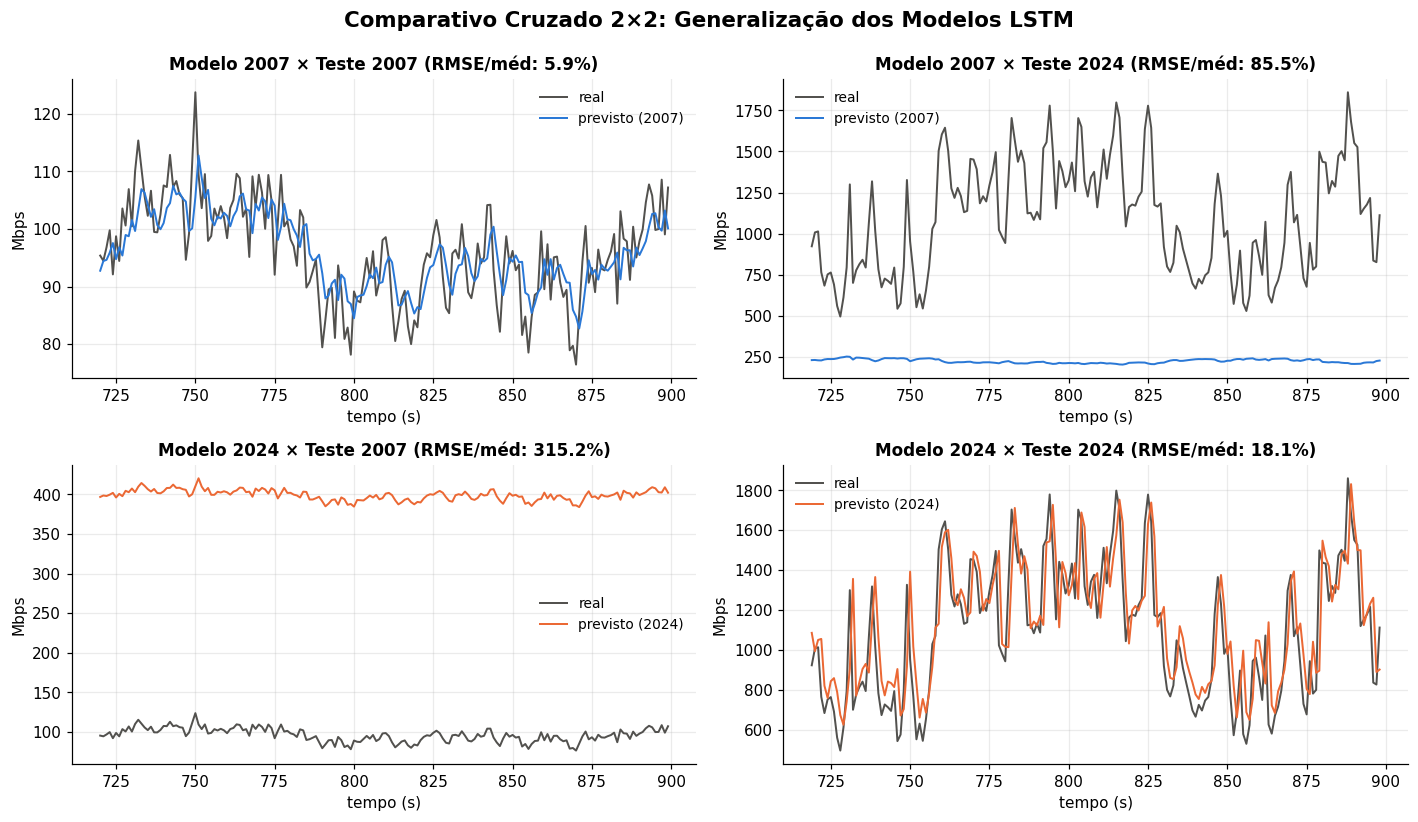

In [ ]:
# TODO: para cada par (ano do modelo, ano de teste): use o MELHOR modelo do ano de treino (T2), o MESMO scaler do ano de treino
#       e a parte de teste da série do outro ano; calcule metricas(real, prev) e a persistência do ano de teste
# TODO: tabela 2x2 (linhas = modelo, colunas = teste) com MSE, RMSE e RMSE/média
# TODO: grade 2x2 de gráficos real × previsto (linhas = modelo, colunas = ano de teste)

ANOS = ['2007', '2024']

# Dicionários para guardar métricas e dados de plotagem
matriz_metricas = {}
dados_plot_t3 = {}

for ano_tr in ANOS:
    # Recupera a melhor janela e o modelo treinado em ano_tr (da Tarefa T2)
    # Suporta se MELHOR guardou apenas a janela int ou a tupla (janela, dict_resultado)
    if isinstance(MELHOR[ano_tr], tuple):
        janela = MELHOR[ano_tr][0]
    else:
        janela = MELHOR[ano_tr]
        
    res_treino = RESULTADOS[(ano_tr, janela)]
    modelo = res_treino['modelo']
    scaler_treino = res_treino['dados']['scaler']
    
    for ano_te in ANOS:
        # Prepara a série de teste usando a janela e o SCALER do ano de treino
        d_te = preparar_dados(SERIES[ano_te], look_back=janela, scaler=scaler_treino)
        
        # Realiza as predições
        real, prev = prever(modelo, d_te)
        
        # Calcula as métricas
        m = metricas(real, prev)
        m_pers = metricas(real, persistencia(d_te))
        
        matriz_metricas[(f"Modelo {ano_tr}", f"Teste {ano_te}")] = {
            'MSE (Mbps²)': m['MSE (Mbps²)'],
            'RMSE (Mbps)': m['RMSE (Mbps)'],
            'RMSE/média (%)': m['RMSE/média (%)'],
            'Persistência (%)': m_pers['RMSE/média (%)']
        }
        
        dados_plot_t3[(ano_tr, ano_te)] = {
            't': d_te['t_te'],
            'real': real,
            'prev': prev,
            'cor': COR[ano_tr],
            'titulo': f"Modelo {ano_tr} × Teste {ano_te} (RMSE/méd: {m['RMSE/média (%)']:.1f}%)"
        }

# Tabela 2x2 de metricas
df_t3 = pd.DataFrame(matriz_metricas).T
df_t3.index = pd.MultiIndex.from_tuples(df_t3.index, names=['Treino', 'Teste'])

print("--- Matriz 2x2: Avaliação Cruzada entre 2007 e 2024 ---")
display(df_t3.round(2))

# graficos
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))

for i, ano_tr in enumerate(ANOS):
    for j, ano_te in enumerate(ANOS):
        ax = axes[i, j]
        p = dados_plot_t3[(ano_tr, ano_te)]
        
        plotar_real_previsto(
            ax=ax,
            t=p['t'],
            real=p['real'],
            prev=p['prev'],
            cor=p['cor'],
            titulo=p['titulo'],
            rotulo_prev=f"previsto ({ano_tr})"
        )

plt.suptitle("Comparativo Cruzado 2×2: Generalização dos Modelos LSTM", fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

